maximum camber(m): 0.0308511002351287
camber location(p): 0.47414602204897116
maximum thickness(t): 0.060013724978081384


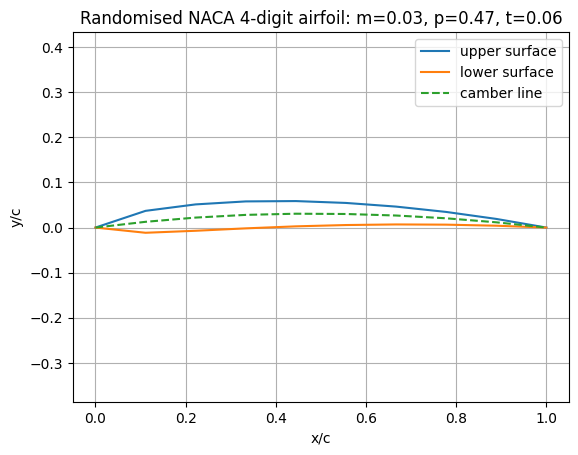

In [3]:
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(1)                             ## fixes the random draw so m, p, t (and all errors) are the same on every run
m=np.random.uniform(0.01, 0.06)               ## realistic range of maximum camber for cambered airfoil
print("maximum camber(m):", m)

p=np.random.uniform(0.15, 0.60)               ## realistic range of camber location for cambered airfoil
print("camber location(p):", p)

t=np.random.uniform(0.06, 0.18)               ## realistic range of maximum thickness for cambered airfoil
print("maximum thickness(t):", t)


def naca_4digit(m,p,t,n=20, x=None):
    if x is None:
        n=int(n/2)
        x=np.linspace(0,1,n)

    yt= 5*t*(0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1036*x**4)  #thickness distribution
    yc=np.where( x<p,
             m/p**2 * (2*p*x - x**2),
             m/(1-p)**2 * ((1-2*p) + 2*p*x - x**2))
    yu=yc + yt
    yl=yc - yt
    return x,yu,yl,yc

xtrue, yutrue, yltrue, yctrue = naca_4digit(m, p, t, n=20)          ## for actual true curve
x, yu, yl, yc= naca_4digit(m, p, t, n=20)                            ## for sparse points on curve

plt.plot(xtrue,yutrue, label="upper surface")
plt.plot(xtrue,yltrue, label="lower surface")
plt.plot(x,yc,'--', label="camber line")
plt.legend()
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.axis("equal")
plt.title(f"Randomised NACA 4-digit airfoil: m={m:.2f}, p={p:.2f}, t={t:.2f}")      ## f here tells to look inside the string and replace them with actual variable and , :.2f also spectifies the no. of decimal places to shoe
plt.grid(True)
plt.show()

In [4]:
xtrue1=np.flip(xtrue)
xtcurve=np.concatenate((xtrue1,xtrue[1:]))
print(xtcurve)

ytrue1=np.flip(yltrue)
ytcurve=np.concatenate((ytrue1,yutrue[1:]))
print(ytcurve)

[1.         0.88888889 0.77777778 0.66666667 0.55555556 0.44444444
 0.33333333 0.22222222 0.11111111 0.         0.11111111 0.22222222
 0.33333333 0.44444444 0.55555556 0.66666667 0.77777778 0.88888889
 1.        ]
[ 8.32857741e-18  4.12577064e-03  6.46283440e-03  6.93418889e-03
  5.60896553e-03  2.70414157e-03 -1.75651765e-03 -7.10420546e-03
 -1.15405237e-02  0.00000000e+00  3.70706668e-02  5.13877426e-02
  5.80166996e-02  5.87559362e-02  5.46143961e-02  4.64976416e-02
  3.46679254e-02  1.91943790e-02 -8.32857741e-18]


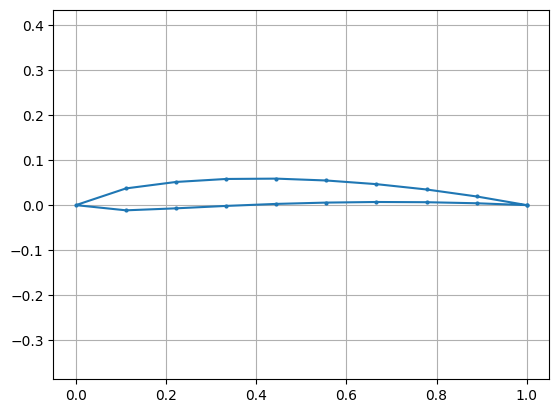

In [5]:
plt.plot(xtcurve,ytcurve,'o-',markersize=2)
plt.axis("equal")            ## for n points there will be n-2 panels as we are eliminating 1 point of the LE while concatenating
plt.grid()
plt.show()


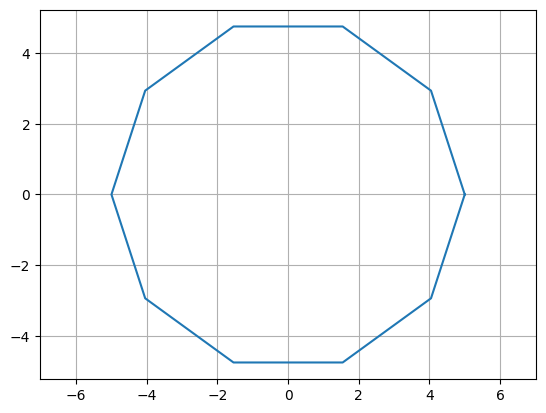

In [10]:
theta=np.linspace(2*np.pi,0,11)
r=5
a=r*np.cos(theta)
b=r*np.sin(theta)
plt.plot(a,b)
plt.axis("equal")
plt.grid()
plt.show()